In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Upload da planilha
arquivo_enviado = files.upload()
arquivo = next(iter(arquivo_enviado))

print("Arquivo recebido:", arquivo)

# Carregar a base principal
df = pd.read_excel(arquivo, sheet_name="CELULAR_2026")

# Garantir o tipo de data
df["DATA_OCORRENCIA_BO"] = pd.to_datetime(df["DATA_OCORRENCIA_BO"],errors="coerce")

print("Base carregada com sucesso!")
print("Dimensões:", df.shape)

# 1. Municípios
print("\nMUNICÍPIOS MAIS FREQUENTES")
print(df["CIDADE"].value_counts().head(20))

# 2. Códigos IBGE
print("\nCÓDIGOS IBGE MAIS FREQUENTES")
print(df["COD IBGE"].value_counts().head(20))

# 3. Naturezas criminais
print("\nNATUREZAS CRIMINAIS")
print(df["RUBRICA"].value_counts().head(30))

# 4. Período das ocorrências
print("\nPERÍODO DOS FATOS")
print("Data inicial:", df["DATA_OCORRENCIA_BO"].min())
print("Data final:", df["DATA_OCORRENCIA_BO"].max())

# 5. Identificação dos boletins
chaves_bo = ["NOME_DELEGACIA", "ANO_BO", "NUM_BO"]

print("\nIDENTIFICAÇÃO DOS BOLETINS")
print("Linhas totais:", len(df))
print(
    "Boletins identificados:",
    df[chaves_bo].drop_duplicates().shape[0]
)
print(
    "Linhas excedentes em relação aos boletins únicos:",
    len(df) - df[chaves_bo].drop_duplicates().shape[0]
)

# 6. Amostra dos registros
print("\nAMOSTRA DOS REGISTROS")
print(
    df[
        ["NOME_MUNICIPIO", "CIDADE", "COD IBGE",
         "DATA_OCORRENCIA_BO", "RUBRICA"]
    ].head(10).to_string(index=False)
)

# 7. Consultar a metodologia
metodologia = pd.read_excel(
    arquivo,
    sheet_name="METODOLOGIA"
)

print("\nMETODOLOGIA")
print(metodologia.to_string(index=False))

# 8. Consultar o dicionário de dados
dicionario = pd.read_excel(
    arquivo,
    sheet_name="DICIONARIO DE DADOS"
)

print("\nDICIONÁRIO DE DADOS")
print(dicionario.to_string(index=False))

# 9. Identificação dos campos geográficos
print("\nCIDADE:")
print(df["CIDADE"].value_counts().head(10))

print("\nMUNICÍPIO DA CIRCUNSCRIÇÃO:")
print(df["NOME_MUNICIPIO_CIRC"].value_counts().head(10))

print("\nCÓDIGO IBGE:")
print(df["COD IBGE"].value_counts().head(10))

# 10. Cruzamento entre campos geográficos
print("\nCRUZAMENTO CIDADE x COD IBGE:")
print(pd.crosstab(df["CIDADE"], df["COD IBGE"]))

print("\nCRUZAMENTO MUNICÍPIO CIRCUNSCRIÇÃO x COD IBGE:")
print(pd.crosstab(df["NOME_MUNICIPIO_CIRC"], df["COD IBGE"]))


Saving CelularesSubtraidos_2026.xlsx to CelularesSubtraidos_2026.xlsx
Arquivo recebido: CelularesSubtraidos_2026.xlsx
Base carregada com sucesso!
Dimensões: (256076, 55)

MUNICÍPIOS MAIS FREQUENTES
CIDADE
S.PAULO                150990
GUARULHOS                7090
CAMPINAS                 5577
S.ANDRE                  4967
OSASCO                   4823
S.BERNARDO DO CAMPO      3834
PRAIA GRANDE             2801
SOROCABA                 2408
RIBEIRAO PRETO           2334
ITAQUAQUECETUBA          2117
DIADEMA                  2049
CARAPICUIBA              1970
SANTOS                   1940
BARUERI                  1826
MOGI DAS CRUZES          1714
S.VICENTE                1707
MAUA                     1689
S.JOSE DOS CAMPOS        1674
S.JOSE DO RIO PRETO      1647
SUZANO                   1529
Name: count, dtype: int64

CÓDIGOS IBGE MAIS FREQUENTES
COD IBGE
3550308    151170
3518800      7078
3509502      5566
3547809      4944
3534401      4797
3548708      3833
3541000      2800
3552

In [ ]:
# Filtrar São Paulo e fatos de 2026
df_sp_2026 = df[(df["COD IBGE"] == 3550308) &(df["DATA_OCORRENCIA_BO"].dt.year == 2026)].copy()

print("BASE PROVISÓRIA SP 2026")
print("Quantidade de linhas:", len(df_sp_2026))

print("\nNATUREZAS EM SP 2026:")
print(df_sp_2026["RUBRICA"].value_counts())

BASE PROVISÓRIA SP 2026
Quantidade de linhas: 148830

NATUREZAS EM SP 2026:
RUBRICA
Furto (art. 155)                                        75897
Roubo (art. 157)                                        49107
Perda/Extravio                                          16363
Localização/Apreensão e Entrega de veículo               1337
Outros não criminal                                      1191
                                                        ...  
Abalroamento                                                1
Art. 216A - Assedio Sexual                                  1
Omissão cautela na guarda/condução animais (art. 31)        1
Falsidade ideológica (art. 299)                             1
tráfico drogas (Art.33, caput)                              1
Name: count, Length: 88, dtype: int64


In [ ]:

# Identificação e classificação dos boletins de ocorrência

chaves_bo = ["NOME_DELEGACIA", "ANO_BO", "NUM_BO"]

# Remover boletins sem chave de identificação
df_bo_com_chave = df_sp_2026.dropna(subset=chaves_bo).copy()

# Consolidar as naturezas por BO
bo_consolidados = (df_bo_com_chave.groupby(chaves_bo).agg(
        quantidade_naturezas=("RUBRICA", "nunique"),
        possui_rubrica_nula=("RUBRICA", lambda x: x.isna().any()),
        naturezas=("RUBRICA", lambda x: sorted(x.dropna().astype(str).unique()))).reset_index())

# Selecionar BOs com uma única natureza e sem RUBRICA nula
bo_natureza_unica = bo_consolidados[(bo_consolidados["quantidade_naturezas"] == 1) &(~bo_consolidados["possui_rubrica_nula"])].copy()

# Identificar a natureza criminal
bo_natureza_unica["natureza"] = bo_natureza_unica["naturezas"].str[0]

# Definir as classes de interesse
classes_validas = ["Furto (art. 155)", "Roubo (art. 157)"]

# Filtrar BOs classificáveis
bo_classificaveis = bo_natureza_unica[bo_natureza_unica["natureza"].isin(classes_validas)].copy()

# Criar variável alvo
bo_classificaveis["target"] = bo_classificaveis["natureza"].map({"Furto (art. 155)": 0,"Roubo (art. 157)": 1})

# Verificar resultados
print("BOs COM CHAVE VÁLIDA:", len(bo_consolidados))
print("\nBOs COM NATUREZA ÚNICA E SEM RUBRICA NULA:", len(bo_natureza_unica))
print("\nBOs CLASSIFICÁVEIS (FURTO/ROUBO):", len(bo_classificaveis))

print("\nDISTRIBUIÇÃO DAS NATUREZAS:")
print(bo_classificaveis["natureza"].value_counts())

print("\nDISTRIBUIÇÃO DO TARGET:")
print(bo_classificaveis["target"].value_counts().sort_index())

print("\nPROPORÇÃO DAS CLASSES (%):")
print(bo_classificaveis["target"].value_counts(normalize=True).sort_index().mul(100).round(2))


BOs COM CHAVE VÁLIDA: 128753

BOs COM NATUREZA ÚNICA E SEM RUBRICA NULA: 126327

BOs CLASSIFICÁVEIS (FURTO/ROUBO): 108435

DISTRIBUIÇÃO DAS NATUREZAS:
natureza
Furto (art. 155)    70944
Roubo (art. 157)    37491
Name: count, dtype: int64

DISTRIBUIÇÃO DO TARGET:
target
0    70944
1    37491
Name: count, dtype: int64

PROPORÇÃO DAS CLASSES (%):
target
0    65.43
1    34.57
Name: proportion, dtype: float64


In [ ]:
# Identificação dos boletins
chaves_bo = ["NOME_DELEGACIA", "ANO_BO", "NUM_BO"]
bo_classificaveis["target"]

# Variáveis candidatas para entrada da MLP
features_candidatas = ["BAIRRO", "DESCR_PERIODO", "HORA_OCORRENCIA", "DESCR_TIPOLOCAL", "DESCR_SUBTIPOLOCAL", "DATA_OCORRENCIA_BO"]

# Recuperar as linhas originais dos BOs classificados
df_features = df_sp_2026.merge(bo_classificaveis[chaves_bo], on=chaves_bo,how="inner")

# Verificar quantos valores diferentes cada atributo
# apresenta dentro de um mesmo boletim
variacao_features = (df_features.groupby(chaves_bo)[features_candidatas].nunique(dropna=True))

print("VARIAÇÃO DOS ATRIBUTOS DENTRO DOS BOs")
for coluna in features_candidatas:
    print(f"\n{coluna}")
    print("BOs com mais de um valor:",(variacao_features[coluna] > 1).sum())

# Verificar percentual de ausência por atributo
print("\nPERCENTUAL DE AUSÊNCIA NAS LINHAS ORIGINAIS")
print(df_features[features_candidatas].isna().mean().mul(100).round(2).sort_values(ascending=False))

# Verificar quantidade de categorias
print("\nQUANTIDADE DE VALORES DISTINTOS")
for coluna in features_candidatas:
    print(coluna, ":", df_features[coluna].nunique(dropna=True))

VARIAÇÃO DOS ATRIBUTOS DENTRO DOS BOs

BAIRRO
BOs com mais de um valor: 91

DESCR_PERIODO
BOs com mais de um valor: 0

HORA_OCORRENCIA
BOs com mais de um valor: 0

DESCR_TIPOLOCAL
BOs com mais de um valor: 39

DESCR_SUBTIPOLOCAL
BOs com mais de um valor: 42

DATA_OCORRENCIA_BO
BOs com mais de um valor: 0

PERCENTUAL DE AUSÊNCIA NAS LINHAS ORIGINAIS
DESCR_PERIODO         60.77
HORA_OCORRENCIA       39.23
BAIRRO                 0.22
DESCR_TIPOLOCAL        0.00
DESCR_SUBTIPOLOCAL     0.00
DATA_OCORRENCIA_BO     0.00
dtype: float64

QUANTIDADE DE VALORES DISTINTOS
BAIRRO : 1800
DESCR_PERIODO : 5
HORA_OCORRENCIA : 6353
DESCR_TIPOLOCAL : 28
DESCR_SUBTIPOLOCAL : 179
DATA_OCORRENCIA_BO : 273


In [ ]:
print("=== DIAGNÓSTICO DA ORIGEM DOS DADOS ===")

print("\n1. df original:")
print(df.shape)

print("\n2. df_sp_2026:")
print(df_sp_2026.shape)

print("\n3. bo_consolidados:")
print(bo_consolidados.shape)

print("\n4. bo_natureza_unica:")
print(bo_natureza_unica.shape)

print("\n5. bo_classificaveis:")
print(bo_classificaveis.shape)

print("\n6. Distribuição das naturezas classificáveis:")
print(bo_classificaveis["natureza"].value_counts(dropna=False))

print("\n7. Distribuição do target:")
print(bo_classificaveis["target"].value_counts(dropna=False))

print("\n8. Verificação das chaves:")
print("Chaves em df_sp_2026:")
print(df_sp_2026[chaves_bo].drop_duplicates().shape)

print("Chaves em bo_classificaveis:")
print(bo_classificaveis[chaves_bo].drop_duplicates().shape)

print("\n9. Resultado do cruzamento:")
teste_merge = df_sp_2026.merge(bo_classificaveis[chaves_bo + ["target"]], on=chaves_bo, how="inner")
print(teste_merge.shape)

=== DIAGNÓSTICO DA ORIGEM DOS DADOS ===

1. df original:
(256076, 55)

2. df_sp_2026:
(148830, 55)

3. bo_consolidados:
(128753, 6)

4. bo_natureza_unica:
(126327, 7)

5. bo_classificaveis:
(108435, 8)

6. Distribuição das naturezas classificáveis:
natureza
Furto (art. 155)    70944
Roubo (art. 157)    37491
Name: count, dtype: int64

7. Distribuição do target:
target
0    70944
1    37491
Name: count, dtype: int64

8. Verificação das chaves:
Chaves em df_sp_2026:
(128753, 3)
Chaves em bo_classificaveis:
(108435, 3)

9. Resultado do cruzamento:
(119958, 56)


In [ ]:
# Atributos selecionados para análise
features = ["BAIRRO", "DESCR_PERIODO", "HORA_OCORRENCIA", "DESCR_TIPOLOCAL", "DESCR_SUBTIPOLOCAL", "DATA_OCORRENCIA_BO"]

# Recuperar os registros dos boletins classificados
df_features = df_sp_2026.merge(bo_classificaveis[chaves_bo + ["target"]], on=chaves_bo, how="inner")

# Retornar a moda, tratando empates como ausentes
def obter_moda(serie):
    valores = serie.dropna()

    if valores.empty:
        return np.nan

    frequencias = valores.value_counts()
    maior_frequencia = frequencias.max()
    valores_mais_frequentes = frequencias[frequencias == maior_frequencia]

    if len(valores_mais_frequentes) > 1:
        return np.nan

    return valores_mais_frequentes.index[0]


# Consolidar os atributos em uma linha por BO
df_modelo = (df_features.groupby(chaves_bo)[features].agg(obter_moda).reset_index().merge(bo_classificaveis[chaves_bo + ["target"]], on=chaves_bo, how="inner", validate="one_to_one"))

# Extrair informações temporais
df_modelo["DIA_SEMANA"] = (df_modelo["DATA_OCORRENCIA_BO"].dt.dayofweek)

df_modelo["MES"] = (df_modelo["DATA_OCORRENCIA_BO"].dt.month)

# Verificar resultado da consolidação
print("DIMENSÃO DO DATASET:", df_modelo.shape)

print("\nQUANTIDADE DE BOLETINS:")
print(df_modelo[chaves_bo].drop_duplicates().shape[0])

print("\nAUSÊNCIA POR ATRIBUTO (%):")
print(df_modelo[features + ["DIA_SEMANA", "MES"]].isna().mean().mul(100).round(2).sort_values(ascending=False))

print("\nDISTRIBUIÇÃO DO TARGET:")
print(df_modelo["target"].value_counts())

DIMENSÃO DO DATASET: (108435, 12)

QUANTIDADE DE BOLETINS:
108435

AUSÊNCIA POR ATRIBUTO (%):
DESCR_PERIODO         58.52
HORA_OCORRENCIA       41.48
BAIRRO                 0.25
DESCR_TIPOLOCAL        0.04
DESCR_SUBTIPOLOCAL     0.04
DATA_OCORRENCIA_BO     0.00
DIA_SEMANA             0.00
MES                    0.00
dtype: float64

DISTRIBUIÇÃO DO TARGET:
target
0    70944
1    37491
Name: count, dtype: int64


7

In [ ]:

# Analisar ausência de informações temporais por classe
colunas_temporais = ["HORA_OCORRENCIA","DESCR_PERIODO"]

print("AUSÊNCIA POR CLASSE (%)")

for coluna in colunas_temporais:
    print(f"\n{coluna}")

    ausencia_por_classe = (df_modelo.groupby("target")[coluna].apply(lambda serie: serie.isna().mean() * 100).round(2))

    print(ausencia_por_classe)

# Distribuição das categorias de período
print("\nDISTRIBUIÇÃO DE DESCR_PERIODO")
print(df_modelo["DESCR_PERIODO"].value_counts(dropna=False))

# Exemplos de horários registrados
print("\nEXEMPLOS DE HORA_OCORRENCIA")
print(df_modelo["HORA_OCORRENCIA"].dropna().astype(str).value_counts().head(20))

# Verificar tipos de dados
print("\nTIPOS DE DADOS")
print(df_modelo[["HORA_OCORRENCIA", "DESCR_PERIODO", "DATA_OCORRENCIA_BO"]].dtypes)


AUSÊNCIA POR CLASSE (%)

HORA_OCORRENCIA
target
0    51.70
1    22.14
Name: HORA_OCORRENCIA, dtype: float64

DESCR_PERIODO
target
0    48.30
1    77.86
Name: DESCR_PERIODO, dtype: float64

DISTRIBUIÇÃO DE DESCR_PERIODO
DESCR_PERIODO
NaN                63452
A noite            13356
A tarde            12992
Pela manhã         11415
De madrugada        6887
Em hora incerta      333
Name: count, dtype: int64

EXEMPLOS DE HORA_OCORRENCIA
HORA_OCORRENCIA
19:00:00    1444
20:00:00    1332
18:00:00    1270
21:00:00    1195
18:30:00    1113
19:30:00    1072
22:00:00    1026
20:30:00     908
17:00:00     874
14:00:00     860
23:00:00     837
16:00:00     827
21:30:00     813
15:00:00     812
13:00:00     751
17:30:00     681
12:00:00     665
22:30:00     634
08:00:00     574
11:00:00     574
Name: count, dtype: int64

TIPOS DE DADOS
HORA_OCORRENCIA               object
DESCR_PERIODO                 object
DATA_OCORRENCIA_BO    datetime64[ns]
dtype: object


8

In [ ]:
# Features categóricas selecionadas
features_categoricas = ["BAIRRO", "DESCR_TIPOLOCAL", "DESCR_SUBTIPOLOCAL"]

# Analisar quantidade de categorias e frequência
for coluna in features_categoricas:
    print(f"\n{'=' * 60}")
    print(f"COLUNA: {coluna}")
    print(f"{'=' * 60}")

    frequencias = df_modelo[coluna].value_counts(dropna=False)

    print(f"Quantidade de categorias: {df_modelo[coluna].nunique(dropna=True)}")
    print(f"Quantidade de valores ausentes: {df_modelo[coluna].isna().sum()}")

    print("\n15 categorias mais frequentes:")
    print(frequencias.head(15))

    print("\n15 categorias menos frequentes:")
    print(frequencias[frequencias.index.notna()].tail(15))

    print("\nCategorias com apenas 1 ocorrência:")
    print("Categorias com apenas 1 ocorrência:", (frequencias[frequencias.index.notna()] == 1).sum())


COLUNA: BAIRRO
Quantidade de categorias: 1798
Quantidade de valores ausentes: 270

15 categorias mais frequentes:
BAIRRO
PINHEIROS          4929
BELA VISTA         3397
BARRA FUNDA        2936
VILA MARIANA       2639
SANTO AMARO        2620
BRÁS               2598
CONSOLAÇÃO         2276
JARDIM PAULISTA    1990
SANTANA            1899
ITAIM BIBI         1719
LIBERDADE          1717
REPUBLICA          1628
REPÚBLICA          1485
CONSOLACAO         1378
IPIRANGA           1355
Name: count, dtype: int64

15 categorias menos frequentes:
BAIRRO
VL. ANDRADE                      1
VILA INDEPENDENTE                1
JARDIM CORDEIRO                  1
VILA CONTINENTAL                 1
JARDIM SANTA TEREZA              1
EDUCANDÁRIO                      1
VILA MARIA TRINDADE              1
JARDIM APARECIDA                 1
JARDIM JARAGUÁ                   1
VILA REIS                        1
JARDIM ELIZA                     1
JARDIM TUPA                      1
EMBURA                          

9

In [ ]:
import unicodedata
import re

# Criar uma cópia para preservar o dataset original
df_modelo_preparado = df_modelo.copy()

# Normalizar textos categóricos
def normalizar_categoria(valor):
    if pd.isna(valor):
        return np.nan

    valor = str(valor).strip().upper()

    # Remover acentos
    valor = unicodedata.normalize("NFKD", valor)
    valor = "".join(caractere for caractere in valor if not unicodedata.combining(caractere))

    # Padronizar espaços consecutivos
    valor = re.sub(r"\s+", " ", valor)

    return valor


features_categoricas = ["BAIRRO", "DESCR_TIPOLOCAL", "DESCR_SUBTIPOLOCAL"]

# Aplicar normalização
for coluna in features_categoricas:
    df_modelo_preparado[coluna] = (df_modelo_preparado[coluna].apply(normalizar_categoria))


# Comparar quantidade de categorias antes e depois
print("COMPARAÇÃO DE CATEGORIAS")

for coluna in features_categoricas:
    antes = df_modelo[coluna].nunique()
    depois = df_modelo_preparado[coluna].nunique()

    print(f"\n{coluna}")
    print(f"Antes: {antes}")
    print(f"Depois: {depois}")
    print(f"Redução: {antes - depois}")


# Verificar categorias raras após normalização
print("\nCATEGORIAS COM MENOS DE 20 OCORRÊNCIAS")

for coluna in features_categoricas:
    frequencias = df_modelo_preparado[coluna].value_counts()

    raras = frequencias[frequencias < 20]

    print(f"\n{coluna}")
    print(f"Categorias com menos de 20 registros: {len(raras)}")
    print(f"Registros nessas categorias: {raras.sum()}")


# Verificar relação entre tipo e subtipo de local
print("\nRELAÇÃO ENTRE TIPO E SUBTIPO")

relacao = (df_modelo_preparado.dropna(subset=["DESCR_TIPOLOCAL", "DESCR_SUBTIPOLOCAL"]).groupby("DESCR_SUBTIPOLOCAL")["DESCR_TIPOLOCAL"].nunique().sort_values(ascending=False))

print("Subtipos associados a mais de um tipo:")
print(relacao[relacao > 1].head(20))

print("\nQuantidade de subtipos associados a mais de um tipo:",(relacao > 1).sum())

COMPARAÇÃO DE CATEGORIAS

BAIRRO
Antes: 1798
Depois: 1672
Redução: 126

DESCR_TIPOLOCAL
Antes: 28
Depois: 28
Redução: 0

DESCR_SUBTIPOLOCAL
Antes: 178
Depois: 177
Redução: 1

CATEGORIAS COM MENOS DE 20 OCORRÊNCIAS

BAIRRO
Categorias com menos de 20 registros: 1262
Registros nessas categorias: 6589

DESCR_TIPOLOCAL
Categorias com menos de 20 registros: 7
Registros nessas categorias: 51

DESCR_SUBTIPOLOCAL
Categorias com menos de 20 registros: 129
Registros nessas categorias: 611

RELAÇÃO ENTRE TIPO E SUBTIPO
Subtipos associados a mais de um tipo:
DESCR_SUBTIPOLOCAL
OUTROS                             4
AREA COMUM                         3
CINEMA/TEATRO                      2
POSTO DE GASOLINA                  2
BAZAR                              2
SHOW-ROOM                          2
TRANSEUNTE                         2
SALAO DE BELEZA/ESTETICA           2
PADARIA/CONFEITARIA                2
LOTERICA                           2
FARMACIA/DROGARIA                  2
INTERIOR DE VEICULO DE

In [ ]:
print("=== DIAGNÓSTICO DO DATASET ===")

print("\ndf_modelo:")
print("Dimensões:", df_modelo.shape)
print(df_modelo.head())

print("\nDistribuição do target em df_modelo:")
print(df_modelo["target"].value_counts(dropna=False))

print("\ndf_modelo_preparado:")
print("Dimensões:", df_modelo_preparado.shape)
print(df_modelo_preparado.head())

print("\nColunas disponíveis:")
print(df_modelo_preparado.columns.tolist())

print("\nValores ausentes:")
print(df_modelo_preparado.isna().sum())

=== DIAGNÓSTICO DO DATASET ===

df_modelo:
Dimensões: (108435, 12)
   NOME_DELEGACIA  ANO_BO  NUM_BO                         BAIRRO  \
0  01ª DDM CENTRO    2026  AZ6507                     CONSOLACAO   
1  01ª DDM CENTRO    2026  DB9446  CENTRO HISTÓRICO DE SÃO PAULO   
2  01ª DDM CENTRO    2026  DM0292              PARQUE SAO RAFAEL   
3  01ª DDM CENTRO    2026  EN9475   JARDIM SAO JOSE (ZONA NORTE)   
4  01ª DDM CENTRO    2026  FM0399  CENTRO HISTÓRICO DE SÃO PAULO   

  DESCR_PERIODO HORA_OCORRENCIA   DESCR_TIPOLOCAL  \
0           NaN        00:00:24       Via Pública   
1           NaN        08:50:00       Via Pública   
2    Pela manhã             NaN  Terminal/Estação   
3           NaN        11:00:27             Saúde   
4           NaN        14:00:00  Terminal/Estação   

                        DESCR_SUBTIPOLOCAL DATA_OCORRENCIA_BO  target  \
0                              Via Pública         2026-01-17       1   
1                               Transeunte         2026-02-

In [ ]:
from sklearn.model_selection import train_test_split

# Definir as features selecionadas
features_modelo = ["BAIRRO", "DESCR_TIPOLOCAL", "DESCR_SUBTIPOLOCAL", "DIA_SEMANA", "MES"]

# Separar variáveis independentes e target
X = df_modelo_preparado[features_modelo].copy()
y = df_modelo_preparado["target"].copy()

# Primeira divisão: 70% treino e 30% temporário
X_treino, X_temp, y_treino, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

# Segunda divisão: 15% validação e 15% teste
X_validacao, X_teste, y_validacao, y_teste = train_test_split(X_temp,y_temp,test_size=0.50, random_state=42,stratify=y_temp)


# Verificar dimensões
print("DIMENSÕES DOS CONJUNTOS")

print(f"Treino:     {X_treino.shape}")
print(f"Validação:  {X_validacao.shape}")
print(f"Teste:      {X_teste.shape}")


# Verificar distribuição das classes
print("\nDISTRIBUIÇÃO DAS CLASSES (%)")

for nome, conjunto in [
    ("Treino", y_treino),
    ("Validação", y_validacao),
    ("Teste", y_teste)
]:
    print(f"\n{nome}:")
    print((conjunto.value_counts(normalize=True) * 100).round(2))


# Verificar valores ausentes
print("\nVALORES AUSENTES POR CONJUNTO")

for nome, conjunto in [
    ("Treino", X_treino),
    ("Validação", X_validacao),
    ("Teste", X_teste)
]:
    print(f"\n{nome}:")
    print(conjunto.isna().sum())


# Verificar sobreposição entre os índices
print("\nVERIFICAÇÃO DE SOBREPOSIÇÃO")

indices_treino = set(X_treino.index)
indices_validacao = set(X_validacao.index)
indices_teste = set(X_teste.index)

print("Treino x Validação:", len(indices_treino & indices_validacao))
print("Treino x Teste:", len(indices_treino & indices_teste))
print("Validação x Teste:", len(indices_validacao & indices_teste))

DIMENSÕES DOS CONJUNTOS
Treino:     (75904, 5)
Validação:  (16265, 5)
Teste:      (16266, 5)

DISTRIBUIÇÃO DAS CLASSES (%)

Treino:
target
0    65.42
1    34.58
Name: proportion, dtype: float64

Validação:
target
0    65.43
1    34.57
Name: proportion, dtype: float64

Teste:
target
0    65.42
1    34.58
Name: proportion, dtype: float64

VALORES AUSENTES POR CONJUNTO

Treino:
BAIRRO                194
DESCR_TIPOLOCAL        31
DESCR_SUBTIPOLOCAL     32
DIA_SEMANA              0
MES                     0
dtype: int64

Validação:
BAIRRO                34
DESCR_TIPOLOCAL        2
DESCR_SUBTIPOLOCAL     2
DIA_SEMANA             0
MES                    0
dtype: int64

Teste:
BAIRRO                42
DESCR_TIPOLOCAL        5
DESCR_SUBTIPOLOCAL     7
DIA_SEMANA             0
MES                    0
dtype: int64

VERIFICAÇÃO DE SOBREPOSIÇÃO
Treino x Validação: 0
Treino x Teste: 0
Validação x Teste: 0


In [ ]:
import sklearn
import numpy as np

from scipy.sparse import issparse
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

print("Versão do Scikit-learn:", sklearn.__version__)

# Separar as colunas por tipo
colunas_categoricas = ["BAIRRO", "DESCR_TIPOLOCAL", "DESCR_SUBTIPOLOCAL"]

colunas_numericas = ["DIA_SEMANA", "MES"]

# Pipeline das variáveis categóricas
pipeline_categorico = Pipeline([ ("imputador", SimpleImputer(strategy="constant", fill_value="NAO_INFORMADO")),("codificador", OneHotEncoder(handle_unknown="ignore", min_frequency=20, dtype=np.float32, sparse_output=True))])

# Pipeline das variáveis numéricas
pipeline_numerico = Pipeline([("imputador", SimpleImputer(strategy="median")),("escalonador", StandardScaler())])

# Combinar os pipelines
preprocessador = ColumnTransformer(transformers=[("categoricas", pipeline_categorico, colunas_categoricas),("numericas", pipeline_numerico, colunas_numericas)],remainder="drop")

# Ajustar exclusivamente com os dados de treino
X_treino_processado = preprocessador.fit_transform(X_treino)

# Aplicar as transformações nos demais conjuntos
X_validacao_processado = preprocessador.transform(X_validacao)
X_teste_processado = preprocessador.transform(X_teste)

# Converter para float32 mantendo a representação esparsa, se aplicável
X_treino_processado = X_treino_processado.astype(np.float32)
X_validacao_processado = X_validacao_processado.astype(np.float32)
X_teste_processado = X_teste_processado.astype(np.float32)

# Verificar resultados
print("\nDIMENSÕES APÓS O PRÉ-PROCESSAMENTO")

print("Treino:", X_treino_processado.shape)
print("Validação:", X_validacao_processado.shape)
print("Teste:", X_teste_processado.shape)

print("\nREPRESENTAÇÃO DOS DADOS")
print("Matriz esparsa:", issparse(X_treino_processado))

if issparse(X_treino_processado):

    densidade = (X_treino_processado.nnz /(X_treino_processado.shape[0] *X_treino_processado.shape[1]))

    print(f"Densidade da matriz: {densidade:.4%}")

    print("Memória utilizada no treino:", f"{X_treino_processado.data.nbytes / 1024**2:.2f} MB")

else:

    print("Memória utilizada no treino:", f"{X_treino_processado.nbytes / 1024**2:.2f} MB")

print("\nQUANTIDADE DE FEATURES GERADAS")
print(len(preprocessador.get_feature_names_out()))

print("\nEXEMPLOS DE FEATURES GERADAS")
print(preprocessador.get_feature_names_out()[:30])

Versão do Scikit-learn: 1.6.1

DIMENSÕES APÓS O PRÉ-PROCESSAMENTO
Treino: (75904, 390)
Validação: (16265, 390)
Teste: (16266, 390)

REPRESENTAÇÃO DOS DADOS
Matriz esparsa: True
Densidade da matriz: 1.2821%
Memória utilizada no treino: 1.45 MB

QUANTIDADE DE FEATURES GERADAS
390

EXEMPLOS DE FEATURES GERADAS
['categoricas__BAIRRO_ACLIMACAO' 'categoricas__BAIRRO_AGUA BRANCA'
 'categoricas__BAIRRO_AGUA RASA' 'categoricas__BAIRRO_ALTO DA LAPA'
 'categoricas__BAIRRO_ALTO DA MOOCA'
 'categoricas__BAIRRO_ALTO DE PINHEIROS'
 'categoricas__BAIRRO_AMERICANOPOLIS' 'categoricas__BAIRRO_ANHANGUERA'
 'categoricas__BAIRRO_ARICANDUVA' 'categoricas__BAIRRO_ARTUR ALVIM'
 'categoricas__BAIRRO_BALNEARIO MAR PAULISTA'
 'categoricas__BAIRRO_BALNEARIO SAO FRANCISCO'
 'categoricas__BAIRRO_BARRA FUNDA' 'categoricas__BAIRRO_BELA VISTA'
 'categoricas__BAIRRO_BELEM' 'categoricas__BAIRRO_BELENZINHO'
 'categoricas__BAIRRO_BELEZINHO' 'categoricas__BAIRRO_BOM RETIRO'
 'categoricas__BAIRRO_BOSQUE DA SAUDE' 'categorica

In [ ]:
# Verificar se existem valores ausentes após o pré-processamento
print("VALORES AUSENTES NAS MATRIZES")

for nome, matriz in [("Treino", X_treino_processado), ("Validação", X_validacao_processado), ("Teste", X_teste_processado)]:
    print(f"{nome}: {np.isnan(matriz.data).sum() if issparse(matriz) else np.isnan(matriz).sum()}")

# Converter matrizes esparsas para densas
X_treino_mlp = X_treino_processado.toarray().astype(np.float32)
X_validacao_mlp = X_validacao_processado.toarray().astype(np.float32)
X_teste_mlp = X_teste_processado.toarray().astype(np.float32)

# Preparar os targets no formato de saída da MLP
y_treino_mlp = y_treino.to_numpy(dtype=np.float32).reshape(-1, 1)
y_validacao_mlp = y_validacao.to_numpy(dtype=np.float32).reshape(-1, 1)
y_teste_mlp = y_teste.to_numpy(dtype=np.float32).reshape(-1, 1)

# Verificar dimensões e tipos
print("\nDIMENSÕES FINAIS")

print("Treino:", X_treino_mlp.shape, y_treino_mlp.shape)
print("Validação:", X_validacao_mlp.shape, y_validacao_mlp.shape)
print("Teste:", X_teste_mlp.shape, y_teste_mlp.shape)

print("\nTIPOS DE DADOS")
print("Features:", X_treino_mlp.dtype)
print("Target:", y_treino_mlp.dtype)

print("\nVALORES NÃO FINITOS")
print("Treino:", np.isfinite(X_treino_mlp).all())
print("Validação:", np.isfinite(X_validacao_mlp).all())
print("Teste:", np.isfinite(X_teste_mlp).all())

VALORES AUSENTES NAS MATRIZES
Treino: 0
Validação: 0
Teste: 0

DIMENSÕES FINAIS
Treino: (75904, 390) (75904, 1)
Validação: (16265, 390) (16265, 1)
Teste: (16266, 390) (16266, 1)

TIPOS DE DADOS
Features: float32
Target: float32

VALORES NÃO FINITOS
Treino: True
Validação: True
Teste: True


In [ ]:
import tensorflow as tf
import random
import numpy as np

# Definir sementes para reprodutibilidade
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Verificar ambiente
print("TensorFlow:", tf.__version__)
print("Dispositivos disponíveis:", tf.config.list_physical_devices())

# Parâmetros gerais de treinamento
EPOCAS = 100
BATCH_SIZE = 256
LEARNING_RATE = 0.001

print("\nCONFIGURAÇÕES")
print("Épocas máximas:", EPOCAS)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Quantidade de entradas:", X_treino_mlp.shape[1])

TensorFlow: 2.21.0
Dispositivos disponíveis: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]

CONFIGURAÇÕES
Épocas máximas: 100
Batch size: 256
Learning rate: 0.001
Quantidade de entradas: 390


In [ ]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.metrics import (BinaryAccuracy,
Precision, Recall, AUC)

# Arquiteturas que serão comparadas
arquiteturas = {
    "MLP_1_Compacta": [64, 32],
    "MLP_2_Larga": [128, 64],
    "MLP_3_Profunda": [64, 32, 16]
}


def criar_modelo(neuronios_ocultos):
    modelo = Sequential()

    modelo.add(Input(shape=(X_treino_mlp.shape[1],)))

    for quantidade_neuronios in neuronios_ocultos:
        modelo.add(Dense(quantidade_neuronios, activation="relu"))

    modelo.add(Dense(1,activation="sigmoid"))

    modelo.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE),
        loss=BinaryCrossentropy(),
        metrics=[BinaryAccuracy(name="accuracy"),Precision(name="precision"),Recall(name="recall"),AUC(name="auc")])

    return modelo


# Visualizar quantidade de parâmetros
for nome, camadas in arquiteturas.items():
    tf.keras.utils.set_random_seed(SEED)

    modelo = criar_modelo(camadas)

    print(f"\n{nome}")
    modelo.summary()


MLP_1_Compacta


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_14 (Dense)                │ (None, 64)             │        25,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,137 (106.00 KB)

 Trainable params: 27,137 (106.00 KB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_20 (Dense)                │ (None, 64)             │        25,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,649 (108.00 KB)

 Trainable params: 27,649 (108.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

modelos_treinados = {}
historicos = {}

for nome, camadas in arquiteturas.items():

    print(f"\n{'=' * 60}")
    print(f"TREINANDO: {nome}")
    print(f"{'=' * 60}")

    # Reiniciar semente para cada arquitetura
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    modelo = criar_modelo(camadas)

    # Interromper treinamento quando a validação deixar de melhorar
    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    )

    historico = modelo.fit(X_treino_mlp,y_treino_mlp,validation_data=(X_validacao_mlp, y_validacao_mlp), epochs=EPOCAS, batch_size=BATCH_SIZE, callbacks=[early_stopping], verbose=1)

    modelos_treinados[nome] = modelo
    historicos[nome] = historico

    melhor_epoca = np.argmin(historico.history["val_loss"]) + 1

    print(f"\nMelhor época: {melhor_epoca}")
    print(f"Menor val_loss: {min(historico.history['val_loss']):.4f}")


TREINANDO: MLP_1_Compacta
Epoch 1/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.6889 - auc: 0.6909 - loss: 0.5915 - precision: 0.6147 - recall: 0.2684 - val_accuracy: 0.7139 - val_auc: 0.7287 - val_loss: 0.5658 - val_precision: 0.6198 - val_recall: 0.4462
Epoch 2/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7135 - auc: 0.7305 - loss: 0.5639 - precision: 0.6188 - recall: 0.4462 - val_accuracy: 0.7150 - val_auc: 0.7313 - val_loss: 0.5636 - val_precision: 0.6216 - val_recall: 0.4485
Epoch 3/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7162 - auc: 0.7349 - loss: 0.5606 - precision: 0.6237 - recall: 0.4520 - val_accuracy: 0.7155 - val_auc: 0.7326 - val_loss: 0.5630 - val_precision: 0.6224 - val_recall: 0.4499
Epoch 4/100
297/297 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7173 - auc: 0.7379 - loss: 0.5582 - precision: 0.6259 - recall: 0.4536 - val_accuracy: 0.7172 - val_auc: 0.7331 - val_loss: 0.5627 - val_precision: 0.6268 - val_recall: 0.4496
E

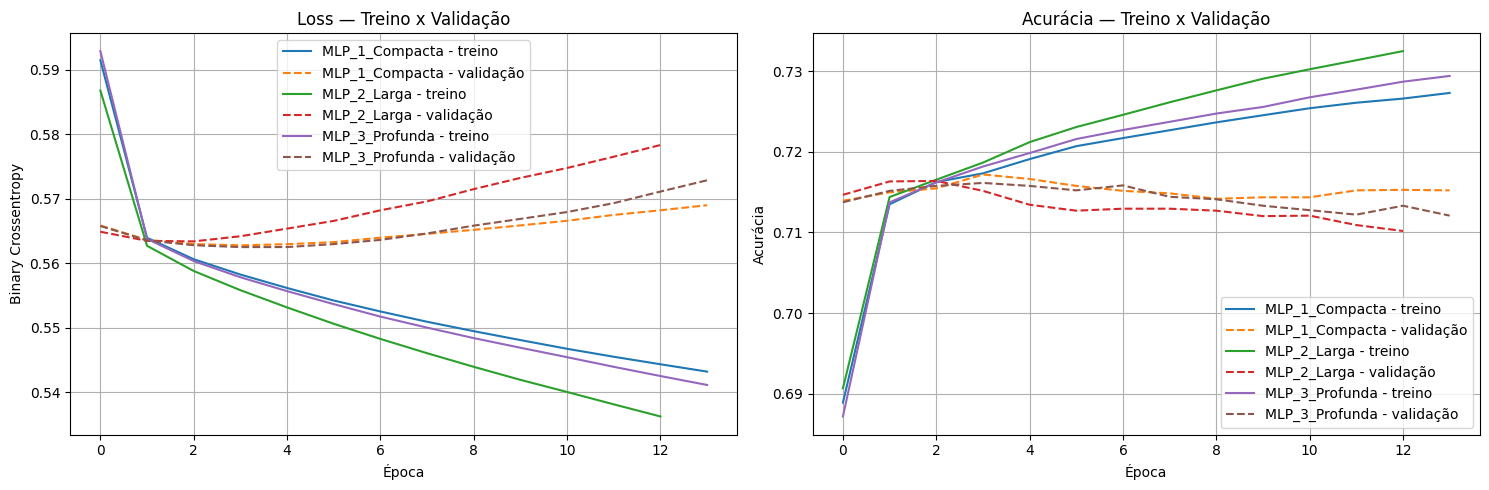

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for nome, historico in historicos.items():
    # Curva de loss
    axes[0].plot(historico.history["loss"], label=f"{nome} - treino")
    axes[0].plot(historico.history["val_loss"], linestyle="--", label=f"{nome} - validação")

    # Curva de accuracy
    axes[1].plot(historico.history["accuracy"], label=f"{nome} - treino")
    axes[1].plot(historico.history["val_accuracy"], linestyle="--", label=f"{nome} - validação")

axes[0].set_title("Loss — Treino x Validação")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Binary Crossentropy")
axes[0].legend()
axes[0].grid(True)

axes[1].set_title("Acurácia — Treino x Validação")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Acurácia")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix)

y_validacao_real = y_validacao_mlp.ravel()

resultados_validacao = []

matrizes_confusao = {}

for nome, modelo in modelos_treinados.items():

    # Probabilidades previstas para a classe Roubo
    probabilidades = modelo.predict(X_validacao_mlp,verbose=0).ravel()

    # Classificação usando limiar padrão de 0.5
    y_predito = (probabilidades >= 0.5).astype(int)

    resultados_validacao.append({"Arquitetura": nome,"Accuracy": accuracy_score(y_validacao_real, y_predito),
        "Precision": precision_score(y_validacao_real, y_predito),
        "Recall": recall_score(y_validacao_real, y_predito),
        "F1-score": f1_score(y_validacao_real, y_predito),
        "ROC-AUC": roc_auc_score(y_validacao_real, probabilidades)})

    matrizes_confusao[nome] = confusion_matrix(y_validacao_real, y_predito)

df_resultados_validacao = pd.DataFrame(resultados_validacao)

display(df_resultados_validacao.sort_values(by="F1-score", ascending=False).round(4))

print("\nMATRIZES DE CONFUSÃO")
for nome, matriz in matrizes_confusao.items():
    print(f"\n{nome}")
    print(matriz)

,Arquitetura,Accuracy,Precision,Recall,F1-score,ROC-AUC
2,MLP_3_Profunda,0.7161,0.6205,0.4606,0.5287,0.7336
1,MLP_2_Larga,0.7164,0.6225,0.4565,0.5267,0.7320
0,MLP_1_Compacta,0.7172,0.6268,0.4496,0.5236,0.7331



MATRIZES DE CONFUSÃO

MLP_1_Compacta
[[9137 1505]
 [3095 2528]]

MLP_2_Larga
[[9085 1557]
 [3056 2567]]

MLP_3_Profunda
[[9058 1584]
 [3033 2590]]


In [ ]:
# Arquitetura selecionada com base nas métricas de validação

nome_modelo_escolhido = "MLP_3_Profunda"

modelo_final = modelos_treinados[nome_modelo_escolhido]

print("Modelo selecionado:", nome_modelo_escolhido)
print("Arquitetura:", arquiteturas[nome_modelo_escolhido])
print("Melhor época:",
      np.argmin(historicos[nome_modelo_escolhido].history["val_loss"]) + 1)

print("\nModelo:")
modelo_final.summary()

Modelo selecionado: MLP_3_Profunda
Arquitetura: [64, 32, 16]
Melhor época: 4

Modelo:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        25,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 82,949 (324.02 KB)

 Trainable params: 27,649 (108.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 55,300 (216.02 KB)

RESULTADOS FINAIS — CONJUNTO DE TESTE

Accuracy: 0.716
Precision: 0.6199
Recall: 0.4619
F1-score: 0.5294
ROC-AUC: 0.7281

RELATÓRIO DE CLASSIFICAÇÃO

              precision    recall  f1-score   support

       Furto     0.7494    0.8503    0.7967     10642
       Roubo     0.6199    0.4619    0.5294      5624

    accuracy                         0.7160     16266
   macro avg     0.6846    0.6561    0.6630     16266
weighted avg     0.7046    0.7160    0.7043     16266



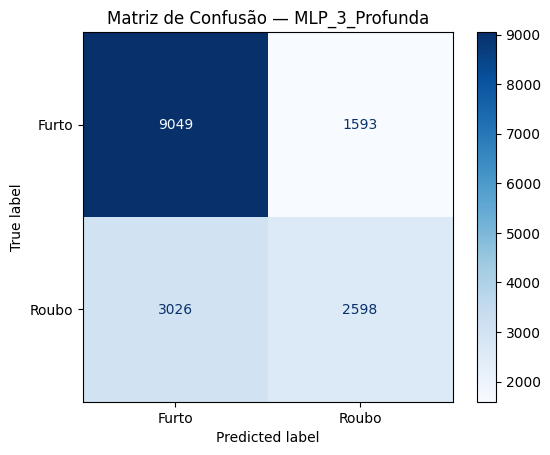

In [ ]:
from sklearn.metrics import (
classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score)

import matplotlib.pyplot as plt

# Valores reais do conjunto de teste
y_teste_real = y_teste_mlp.ravel()

# Probabilidades previstas
y_teste_prob = modelo_final.predict(X_teste_mlp,verbose=0).ravel()

# Classes previstas usando limiar 0.5
y_teste_pred = (y_teste_prob >= 0.5).astype(int)

# Métricas
print("RESULTADOS FINAIS — CONJUNTO DE TESTE\n")

print("Accuracy:", round(accuracy_score(y_teste_real, y_teste_pred), 4))

print("Precision:", round(precision_score(y_teste_real, y_teste_pred), 4))

print("Recall:", round(recall_score(y_teste_real, y_teste_pred), 4))

print("F1-score:", round(f1_score(y_teste_real, y_teste_pred), 4))

print("ROC-AUC:", round(roc_auc_score(y_teste_real, y_teste_prob), 4))

print("\nRELATÓRIO DE CLASSIFICAÇÃO\n")

print(classification_report(y_teste_real, y_teste_pred, target_names=["Furto", "Roubo"], digits=4))

# Matriz de confusão
matriz = confusion_matrix(
    y_teste_real,
    y_teste_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Furto", "Roubo"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de Confusão — MLP_3_Profunda")
plt.show()

## Avaliação Final do Modelo

---

A arquitetura MLP_3_Profunda, composta por três camadas ocultas com 64, 32 e 16 neurônios, foi selecionada com base nos resultados do conjunto de validação. Na avaliação final, utilizando o conjunto de teste independente e limiar de classificação de 0,5, obteve accuracy de 71,60%, precision de 61,99%, recall de 46,19%, F1-score de 52,94% e ROC-AUC de 72,81%.

A matriz de confusão demonstrou melhor identificação da classe Furto, com recall de 85,03%, em comparação à classe Roubo, com recall de 46,19%. Isso indica que o modelo apresenta dificuldade em identificar parte significativa dos registros classificados como Roubo.

Os resultados de validação e teste foram próximos, sugerindo estabilidade do desempenho nessa divisão dos dados. Entretanto, o desempenho ainda é moderado e apresenta limitações na identificação de roubos. Portanto, o modelo deve ser interpretado como uma ferramenta experimental de classificação de registros de ocorrências, e não como um sistema de previsão de crimes ou instrumento autônomo de decisão.


In [ ]:
print("Modelo:", "modelo_final" in globals())
print("Preprocessador:", "preprocessador" in globals())

Modelo: True
Preprocessador: True


In [ ]:
import joblib

# Salvar a rede neural
modelo_final.save("/content/modelo_final.keras")

# Salvar o preprocessador
joblib.dump(preprocessador, "/content/preprocessador.joblib")

print("Arquivos salvos com sucesso!")

Arquivos salvos com sucesso!


In [ ]:
import joblib
import pandas as pd
import numpy as np
from tensorflow.keras.models import load_model

preprocessador = joblib.load("/content/preprocessador.joblib")
modelo = load_model("/content/modelo_final.keras", compile=False)

# Cria um registro de teste com categorias aprendidas no treinamento
encoder = (preprocessador.named_transformers_["categoricas"].named_steps["codificador"])

entrada_teste = pd.DataFrame([{
    "BAIRRO": encoder.categories_[0][0],
    "DESCR_TIPOLOCAL": encoder.categories_[1][0],
    "DESCR_SUBTIPOLOCAL": encoder.categories_[2][0],
    "DIA_SEMANA": 0,
    "MES": 1}])

dados = preprocessador.transform(entrada_teste)

if hasattr(dados, "toarray"):
    dados = dados.toarray()

dados = np.asarray(dados, dtype=np.float32)

print("Formato dos dados:", dados.shape)
print("Entradas esperadas pelo modelo:", modelo.input_shape)
assert dados.shape[1] == modelo.input_shape[1], ("Quantidade de features incompatível com o modelo!")

predicao = modelo.predict(dados, verbose=0)

print("Predição de teste:", predicao)
assert predicao.shape == (1, 1)
assert np.isfinite(predicao).all()
assert 0 <= predicao[0][0] <= 1

print("Teste integrado concluído com sucesso.")
print(f"Probabilidade estimada de Roubo: {predicao[0][0]:.4f}")
print(f"Probabilidade estimada de Furto: {1 - predicao[0][0]:.4f}")


Formato dos dados: (1, 390)
Entradas esperadas pelo modelo: (None, 390)
Predição de teste: [[0.6817717]]
Teste integrado concluído com sucesso.
Probabilidade estimada de Roubo: 0.6818
Probabilidade estimada de Furto: 0.3182
